<p style="text-align:center"><img src="../../../Images/Banner/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Scalable Processing: Dask, GPUs and Batch Jobs

Earlier notebooks ran on one core. Cloud GIS work quickly outgrows that: a national time series has
hundreds of images, a trend test compares every date with every other date in every pixel, and a
continental mosaic reads terabytes from object storage. This notebook takes one real workload and
scales it, measuring every step on this machine, so the effect of each technique is visible:

> **Where in Bangladesh is vegetation getting greener or browner?** For every 1 km land pixel,
> estimate the trend of monthly NDVI anomalies from 25 years of MODIS images (2000-2024) with the
> Theil-Sen estimator.

The Theil-Sen slope is the median of the slopes between all pairs of dates. With about 300 months,
that is about 44,000 slopes per pixel, and Bangladesh has about 146,000 land pixels: some 6.5
billion slopes. The calculation is simple, embarrassingly parallel and heavy, a typical
cloud-scale job.



### Learning objectives

1. Find where time goes (input/output, computation, memory bandwidth, network) before parallelising.
2. Build lazy, chunked pipelines with xarray and Dask, and choose chunk shapes for the access pattern (Zarr).
3. Scale a per-pixel computation across processes with Dask, and read the speed-up curve (Amdahl's law).
4. Move the same kernel to a GPU with CuPy and compare cost and speed.
5. Read many cloud-hosted COGs in parallel, and measure when the network becomes the limit.
6. Split work into independent batch jobs (the pattern behind serverless and cloud batch services),
   and estimate what a run costs.



### Data

| Data | Source |
|---|---|
| MODIS 16-day NDVI, 1 km, Bangladesh, 2000-2024 (572 GeoTIFFs) | `Data/00_shared/data_remote_sensing/MODIS/MODIS_NDVI_BD/` |
| Sentinel-2 L2A red band over Syracuse, NY, April-October 2025 | Earth Search STAC (AWS `sentinel-cogs`), read remotely |
| District boundaries of Bangladesh (for the summary) | `Data/00_shared/data_web_cloud_gis/08_03_outputs/districts.gpkg` (Notebook 08_03) |

Install: `pip install "dask[distributed]" xarray rioxarray zarr pystac-client`, and `cupy-cuda13x`
(or the CuPy build for your CUDA version) for Section 6. The GPU section is skipped on machines
without a CUDA GPU.



### Contents

1. Setup
2. Scaling in one page
3. The workload and its input: reading 572 images
4. Lazy pipelines with xarray and Dask
5. Chunks matter: the same cube in two Zarr layouts
6. Parallel computation with Dask
7. The same kernel on a GPU
8. The result: greening and browning of Bangladesh
9. Reading from the cloud in parallel
10. Batch jobs: the serverless pattern, and what a run costs
11. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `psutil`, which no GeoLattice option installs: `pip install psutil`.

In [1]:
# Imports, quiet logging, paths, optional GPU, and MODIS inventory for scalable NDVI work
%matplotlib inline
import json
import os
import shutil
import subprocess
import sys
import time
import warnings
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
from pathlib import Path

warnings.filterwarnings("ignore")
import logging
for name in ["distributed", "tornado", "tornado.application", "asyncio"]:
    logging.getLogger(name).setLevel(logging.CRITICAL)     # keep cluster start/stop messages out of the output

import numpy as np
import pandas as pd
import geopandas as gpd
import psutil
import rasterio
from rasterio.features import geometry_mask
from shapely.geometry import mapping
import matplotlib.pyplot as plt
import xarray as xr
import rioxarray
import zarr
import dask
import dask.array as da
from dask.distributed import Client, LocalCluster
from osgeo import gdal

import geolattice
import geolattice.web as web

# Output folder, GPU probe, and list of MODIS GeoTIFF inputs
gdal.UseExceptions()
plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
WEB = DATA / "00_shared" / "data_web_cloud_gis"
MODIS = DATA / "00_shared" / "data_remote_sensing" / "MODIS" / "MODIS_NDVI_BD"
OUT = WEB / "08_08_outputs"
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir(parents=True)

try:
    import cupy as cp
    GPU = cp.cuda.runtime.getDeviceCount() > 0
except Exception:
    cp, GPU = None, False

files = sorted(MODIS.glob("ndvi_*.tif"), key=lambda p: (int(p.stem.split("_")[1]), int(p.stem.split("_")[2])))
dates = pd.to_datetime([f"{p.stem.split('_')[1]}-{p.stem.split('_')[2]}" for p in files], format="%Y-%j")
mem = psutil.virtual_memory()
print(f"geolattice {geolattice.__version__} | Dask {dask.__version__} | xarray {xr.__version__} | Zarr {zarr.__version__}")
print(f"CPU: {psutil.cpu_count(logical=False)} physical cores, {psutil.cpu_count()} logical | RAM {mem.total / 1e9:.0f} GB")
print("GPU:", cp.cuda.runtime.getDeviceProperties(0)["name"].decode() + f", {cp.cuda.Device(0).mem_info[1] / 1e9:.0f} GB" if GPU else "none")
print(f"MODIS: {len(files)} images, {dates[0].date()} to {dates[-1].date()}, {sum(f.stat().st_size for f in files) / 1e6:.0f} MB on disk")

geolattice 0.3.11 | Dask 2026.7.1 | xarray 2026.7.0 | Zarr 3.1.6
CPU: 16 physical cores, 24 logical | RAM 132 GB
GPU: NVIDIA RTX A5500 Laptop GPU, 17 GB
MODIS: 572 images, 2000-02-18 to 2024-12-18, 206 MB on disk


## Scaling in one page

| Bottleneck | Symptom | Remedy |
|---|---|---|
| **Computation** (CPU-bound) | One core at 100 % | Parallel processes (Dask, `multiprocessing`), vectorisation, GPUs |
| **Memory bandwidth** | More cores stop helping well before all are busy | Smaller chunks that fit in cache, fewer temporary arrays, GPUs (much higher bandwidth) |
| **Memory capacity** | Out-of-memory errors | Chunked, lazy processing (Dask), out-of-core formats (Zarr) |
| **Disk or network input/output** | Cores idle while waiting | Concurrent requests, cloud-optimised formats, compute next to the data |
| **Python's GIL** | Threads do not run Python code in parallel | Processes, or libraries that release the GIL (NumPy, GDAL) |

**Amdahl's law**: if a fraction *p* of the work can run in parallel, *N* workers give at most a
speed-up of 1 / ((1 − p) + p / N). With p = 0.95, even infinite workers give 20×. Scaling therefore
starts with measuring which part of the job takes the time.

**Tools.** On one machine: `concurrent.futures`, joblib, Dask (`LocalCluster`), CuPy and RAPIDS for
GPUs. On clusters: Dask (Kubernetes, HPC, Coiled, Dask Gateway), Ray, Spark with Apache Sedona. As
managed services: AWS Batch, Google Cloud Run jobs and Batch, Azure Batch, serverless functions
(AWS Lambda, Cloud Functions), and platforms such as Planetary Computer, Earth Engine or openEO
(Notebook 08_09).

## The workload and its input: reading 572 images

Every run starts by reading the images. The 572 GeoTIFFs (LZW-compressed, 670 × 480 pixels) are read
serially, with 16 threads, and with 8 processes.

In [2]:
# Time a naive loop that opens all 572 MODIS NDVI GeoTIFFs
def read_one(path):
    with rasterio.open(path) as src:
        return src.read(1)

timings = {}
t0 = time.perf_counter(); cube = np.stack([read_one(f) for f in files]); timings["serial"] = time.perf_counter() - t0
with ThreadPoolExecutor(16) as ex:
    t0 = time.perf_counter(); c2 = np.stack(list(ex.map(read_one, files))); timings["16 threads"] = time.perf_counter() - t0
with ProcessPoolExecutor(8) as ex:
    list(ex.map(read_one, files[:8]))                                     # start the workers first
    t0 = time.perf_counter(); c3 = np.stack(list(ex.map(read_one, files, chunksize=8))); timings["8 processes"] = time.perf_counter() - t0
assert (c2 == cube).all() and (c3 == cube).all()
with rasterio.open(files[0]) as src:
    crs, transform, shape = src.crs, src.transform, src.shape
print(f"cube {cube.shape}, {cube.nbytes / 1e6:.0f} MB in memory")
pd.Series(timings, name="seconds").round(2).to_frame()

cube (572, 670, 480), 368 MB in memory


,seconds
serial,3.28
16 threads,4.36
8 processes,0.66


Threads made reading *slower* (4.4 s against 3.3 s serially), while 8 processes made it five
times faster (0.66 s). Decompressing the files releases Python's GIL, but rasterio holds it while
opening each file, so threads mostly queue for it. Separate processes each have their own
interpreter and lock. Which kind of parallelism helps depends on the library, so measure it.

## Lazy pipelines with xarray and Dask

The trend is computed on **monthly anomalies**: monthly mean NDVI minus that month's long-term mean,
which removes the seasonal cycle. With xarray and Dask the whole pipeline is written first and only
evaluated at the end, chunk by chunk. Nothing is read until `.compute()` is called.

In [3]:
# Lazy xarray/Dask monthly anomaly pipeline vs eager NumPy on the in-memory cube
t0 = time.perf_counter()
lazy = xr.concat([rioxarray.open_rasterio(f, chunks={"x": 240, "y": 335}).squeeze("band", drop=True) for f in files],
                 dim=pd.Index(dates, name="time"))
ndvi = (lazy.where(lazy != 0) / 1e4).astype("float32")              # 0 marks pixels outside Bangladesh
monthly = ndvi.resample(time="MS").mean()
anomaly = monthly.groupby("time.month") - monthly.groupby("time.month").mean()
build_s = time.perf_counter() - t0
graph = anomaly.data.__dask_graph__()
print(f"pipeline defined in {build_s:.1f} s: {len(graph):,} tasks, {anomaly.data.npartitions} output chunks, "
      f"shape {anomaly.shape}, nothing computed yet")

# Compute the Dask graph with 8 threads
with dask.config.set(scheduler="threads", num_workers=8):
    t0 = time.perf_counter(); anom_dask = anomaly.compute(); dask_s = time.perf_counter() - t0

# Same monthly anomalies with eager NumPy for a correctness check
t0 = time.perf_counter()                                              # the same in eager NumPy, from the cube in memory
v = cube.astype("float32") / 1e4
v[cube == 0] = np.nan
months = dates.to_period("M")
codes, uniq = pd.factorize(months)
mon = np.stack([np.nanmean(v[codes == k], axis=0) for k in range(len(uniq))])
moy = np.array([p.month for p in uniq])
clim = np.stack([np.nanmean(mon[moy == m], axis=0) for m in range(1, 13)])
anom_np = mon - clim[moy - 1]
numpy_s = time.perf_counter() - t0
print(f"Dask (read + compute, 8 threads): {dask_s:.1f} s | NumPy on the cube already in memory: {numpy_s:.1f} s")
print("largest difference between the two:", float(np.nanmax(np.abs(anom_dask.values - anom_np))))

pipeline defined in 5.7 s: 31,165 tasks, 1196 output chunks, shape (299, 670, 480), nothing computed yet


Dask (read + compute, 8 threads): 13.4 s | NumPy on the cube already in memory: 1.6 s


largest difference between the two: 2.980232238769531e-07


The lazy pipeline is a graph of 31,165 tasks over 1,196 chunks, defined in 5.7 s without reading
any pixel data (the time goes into opening the 572 file headers). Computing it with 8 threads took
13.4 s and matched NumPy to 3 × 10⁻⁷. NumPy on the cube already in memory took 1.6 s, so for data
that fit in memory, eager NumPy wins. Dask's value is elsewhere: the same code runs when the cube is
100 times larger than memory, or on a cluster. Its threaded reads also meet the rasterio GIL problem
of Section 3, which a process-based scheduler avoids.

The trend needs only land pixels. We keep pixels that have NDVI on at least 90 % of dates and
arrange the anomalies as a matrix of months × pixels: the input of everything that follows.

In [4]:
# Keep land pixels with good coverage; save the anomaly matrix for trend jobs
land = (cube != 0).mean(axis=0) >= 0.9
A = np.ascontiguousarray(anom_np[:, land]).astype("float32")          # (months, pixels)
n_months, n_pix = A.shape
pairs = n_months * (n_months - 1) // 2
np.save(OUT / "anomalies.npy", A)
print(f"{n_pix:,} land pixels x {n_months} months; {pairs:,} pairs per pixel; "
      f"{pairs * n_pix / 1e9:.1f} billion slopes in total; matrix {A.nbytes / 1e6:.0f} MB")

145,672 land pixels x 299 months; 44,551 pairs per pixel; 6.5 billion slopes in total; matrix 174 MB


## Chunks matter: the same cube in two Zarr layouts

Zarr stores an array as a grid of compressed chunks, each a separate object, which is how large
arrays live in cloud storage. A reader fetches whole chunks, so the chunk shape decides which
questions are cheap. We store the NDVI cube twice: chunked **by date** (one map per chunk, as images
arrive) and chunked **by space** (all dates of a small tile per chunk, for time series), and time the
two typical reads.

In [5]:
# Zarr chunk layout trade-off: fast time series vs fast spatial slices
layouts = {"by date (1 x 670 x 480)": (1, 670, 480), "by space (572 x 64 x 64)": (572, 64, 64)}
rows = []
row, col = 198, 137                                           # a pixel near Bogra
for name, chunks in layouts.items():
    path = OUT / f"ndvi_{chunks[0]}x{chunks[1]}.zarr"
    t0 = time.perf_counter()
    z = zarr.create_array(store=str(path), shape=cube.shape, chunks=chunks, dtype="int16")
    z[:] = cube
    write_s = time.perf_counter() - t0
    z = zarr.open_array(str(path), mode="r")
    t0 = time.perf_counter(); series = z[:, row, col]; series_ms = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); one_map = z[300]; map_ms = (time.perf_counter() - t0) * 1000
    n_files = sum(1 for p in path.rglob("*") if p.is_file())
    rows.append({"layout": name, "chunks (files)": n_files, "MB on disk": round(sum(p.stat().st_size for p in path.rglob('*') if p.is_file()) / 1e6, 1),
                 "write s": round(write_s, 1), "one pixel, all dates (ms)": round(series_ms, 1), "one date, all pixels (ms)": round(map_ms, 1)})
    assert (series == cube[:, row, col]).all() and (one_map == cube[300]).all()
zarr_table = pd.DataFrame(rows).set_index("layout")
zarr_table

,chunks (files),MB on disk,write s,"one pixel, all dates (ms)","one date, all pixels (ms)"
layout,,,,,
by date (1 x 670 x 480),573,151.3,0.4,181.9,1.1
by space (572 x 64 x 64),61,151.6,0.2,5.5,41.3


Both stores hold the same 151 MB, but the costs of the two reads swap:

| Read | Chunked by date | Chunked by space |
|---|---|---|
| One pixel through all 572 dates | 182 ms (opens 572 chunks) | 5.5 ms (opens one chunk) |
| One map on one date | 1.1 ms | 41 ms (opens all 61 chunks) |

On object storage every chunk is a separate HTTP request, so the difference grows. Choose chunks
for the dominant query: by date for map services (Notebook 08_05), by space for time-series APIs
(Notebook 08_06), and compromise shapes or two copies when both matter.

## Parallel computation with Dask

The kernel computes, for a block of pixels, the slopes between all pairs of months and takes their
median. It is plain NumPy, so it runs unchanged on one core, in many processes, or (Section 7) on a
GPU.

In [6]:
# Theil-Sen per pixel (NDVI per decade); time a 20k-pixel serial baseline
def theil_sen(a, xp=np):
    "Median of all pairwise slopes for each column of a (months x pixels); NDVI per decade."
    n = a.shape[0]
    i, j = xp.triu_indices(n, 1)
    slopes = (a[j] - a[i]) / (j - i).astype("float32")[:, None]
    return (xp.nanmedian(slopes, axis=0) * 120).astype("float32")

SUB = 20_000                                                    # a subset for the scaling experiments
t0 = time.perf_counter()
ref = np.concatenate([theil_sen(A[:, k:k + 250]) for k in range(0, SUB, 250)])
serial_s = time.perf_counter() - t0
print(f"serial: {serial_s:.1f} s for {SUB:,} pixels = {serial_s / SUB * 1000:.2f} ms per pixel; "
      f"all {n_pix:,} pixels would take about {serial_s / SUB * n_pix:.0f} s")

serial: 13.6 s for 20,000 pixels = 0.68 ms per pixel; all 145,672 pixels would take about 99 s


Dask splits the pixels into chunks and runs one task per chunk on a cluster of worker processes
(`LocalCluster` here; the same code runs on a cloud cluster by pointing `Client` at it). The input is
read by each worker from a memory-mapped file instead of being copied into the task graph. We vary
the number of workers and the chunk size on the 20,000-pixel subset.

,workers,chunk (pixels),tasks,seconds,speed-up,efficiency
0,1,250,80,15.79,0.86,0.86
1,2,250,80,8.33,1.64,0.82
2,4,250,80,4.79,2.84,0.71
3,8,250,80,3.45,3.96,0.49
4,8,1000,20,3.51,3.88,0.49
5,16,250,80,4.06,3.36,0.21
6,16,1000,20,3.52,3.88,0.24


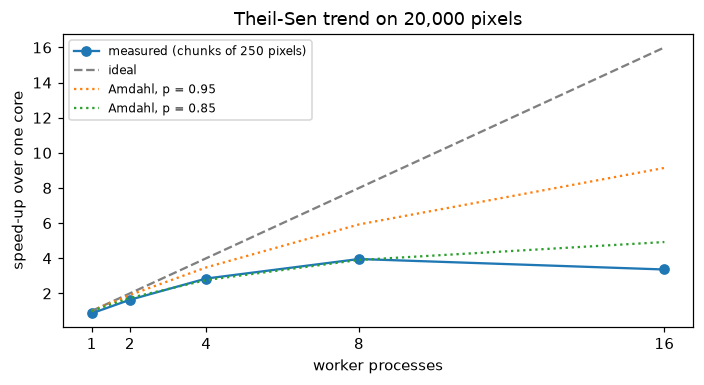

In [7]:
# Scale Theil-Sen with Dask LocalCluster; plot speed-up vs ideal and Amdahl curves
np.save(OUT / "subset.npy", A[:, :SUB])
rows = []
for workers in [1, 2, 4, 8, 16]:
    with LocalCluster(n_workers=workers, threads_per_worker=1, processes=True, dashboard_address=None,
                      silence_logs=logging.CRITICAL) as cluster, Client(cluster):
        for chunk in ([250, 1000] if workers in (8, 16) else [250]):
            x = da.from_array(np.load(OUT / "subset.npy", mmap_mode="r"), chunks=(n_months, chunk), asarray=True)
            t0 = time.perf_counter()
            res = x.map_blocks(theil_sen, drop_axis=0, dtype="float32").compute()
            sec = time.perf_counter() - t0
            assert np.allclose(res, ref, equal_nan=True)
            rows.append({"workers": workers, "chunk (pixels)": chunk, "tasks": SUB // chunk, "seconds": sec,
                         "speed-up": serial_s / sec, "efficiency": serial_s / sec / workers})
scaling = pd.DataFrame(rows)
display(scaling.round(2))

# Speed-up plot for 250-pixel chunks
best = scaling[scaling["chunk (pixels)"] == 250]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(best.workers, best["speed-up"], "o-", label="measured (chunks of 250 pixels)")
ax.plot(best.workers, best.workers, "--", color="grey", label="ideal")
for p in [0.95, 0.85]:
    ax.plot(best.workers, 1 / ((1 - p) + p / best.workers), ":", label=f"Amdahl, p = {p}")
ax.set_xlabel("worker processes"); ax.set_ylabel("speed-up over one core"); ax.set_xticks(best.workers)
ax.set_title("Theil-Sen trend on 20,000 pixels"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

On one core the kernel needs 0.68 ms per pixel, about 99 s for the whole country.

- **Scaling was good up to 4 workers** (2.8×, efficiency 0.71), then flattened: 4.0× with 8
  workers and 3.4-3.9× with 16.
- **One Dask worker was slower than plain serial code** (efficiency 0.86): that is the cost of the
  scheduler.
- **Chunk size mattered little** at 8 workers (3.5 s with chunks of 250 or 1,000 pixels).

The flat part is not Amdahl's serial fraction; this kernel has almost none. Each task builds a
temporary array of 44,551 slopes per pixel and then sorts it, so the cores compete for memory
bandwidth. The laptop's 16 physical cores also share caches and memory channels. Measured scaling,
not the core count, tells you how many workers are worth paying for.

## The same kernel on a GPU

CuPy mirrors NumPy's interface on NVIDIA GPUs, so `theil_sen(a, xp=cp)` runs the same code there.
Each block of pixels is copied to the GPU, processed, and the result copied back. We time the copy
and the computation separately, then process all land pixels on the GPU and with Dask on the CPU.

In [8]:
# Full-country Theil-Sen: optional GPU, then Dask with 8 workers; compare wall times
# Optional CuPy path: measure copy + compute cost, then full-array timing
if GPU:
    theil_sen(cp.asarray(A[:, :100]), xp=cp); cp.cuda.Device().synchronize()      # compile kernels once
    rows = []
    for block in [1000, 2000, 4000]:
        blk = A[:, :block]
        t0 = time.perf_counter(); g = cp.asarray(blk); cp.cuda.Device().synchronize(); up = time.perf_counter() - t0
        t0 = time.perf_counter(); r = theil_sen(g, xp=cp); cp.cuda.Device().synchronize(); comp = time.perf_counter() - t0
        t0 = time.perf_counter(); r = r.get(); down = time.perf_counter() - t0
        rows.append({"block (pixels)": block, "copy to GPU ms": up * 1000, "compute ms": comp * 1000, "copy back ms": down * 1000,
                     "ms per 1,000 pixels": (up + comp + down) / block * 1e6,
                     "GPU memory used GB": round((block * pairs * 4 * 2) / 1e9, 2)})
        assert np.allclose(r, ref[:block], equal_nan=True, atol=1e-5)
    display(pd.DataFrame(rows).round(1))

    t0 = time.perf_counter()
    trend_gpu = np.concatenate([theil_sen(cp.asarray(A[:, k:k + 2000]), xp=cp).get() for k in range(0, n_pix, 2000)])
    gpu_full = time.perf_counter() - t0
    print(f"GPU, all {n_pix:,} pixels: {gpu_full:.1f} s")
else:
    trend_gpu, gpu_full = None, None
    print("No CUDA GPU: skipped")

# Dask LocalCluster over all land pixels
with LocalCluster(n_workers=8, threads_per_worker=1, processes=True, dashboard_address=None,
                      silence_logs=logging.CRITICAL) as cluster, Client(cluster):
    x = da.from_array(np.load(OUT / "anomalies.npy", mmap_mode="r"), chunks=(n_months, 250), asarray=True)
    t0 = time.perf_counter()
    trend = x.map_blocks(theil_sen, drop_axis=0, dtype="float32").compute()
    dask_full = time.perf_counter() - t0
print(f"Dask, 8 workers, all {n_pix:,} pixels: {dask_full:.1f} s")
if GPU:
    print("largest difference GPU vs CPU:", float(np.nanmax(np.abs(trend_gpu - trend))))
full_runs = pd.DataFrame({"seconds": {"1 core (estimated from the subset)": serial_s / SUB * n_pix,
                                      "Dask, 8 processes": dask_full, "GPU (CuPy)": gpu_full}})
full_runs["speed-up"] = full_runs.seconds.iloc[0] / full_runs.seconds
full_runs.round(1)

,block (pixels),copy to GPU ms,compute ms,copy back ms,"ms per 1,000 pixels",GPU memory used GB
0,1000,1.1,67.7,0.1,68.9,0.4
1,2000,2.2,135.5,0.1,68.9,0.7
2,4000,4.0,269.7,0.1,68.4,1.4


GPU, all 145,672 pixels: 9.9 s


Dask, 8 workers, all 145,672 pixels: 20.1 s
largest difference GPU vs CPU: 0.0


,seconds,speed-up
1 core (estimated from the subset),99.3,1.0
"Dask, 8 processes",20.1,4.9
GPU (CuPy),9.9,10.0


The GPU computed 1,000 pixels in about 68 ms against 680 ms on one CPU core, ten times faster.
Copying to and from the GPU took only 1-4 ms per block, because each pixel's 299 inputs produce
44,551 slopes on the GPU: much computation per byte transferred, the ideal case for a GPU. Blocks of
2,000 pixels used about 0.7 GB of the GPU's 17 GB.

Whole country:

| Run | Time | Speed-up |
|---|---|---|
| GPU | 9.9 s | 10.0× |
| Dask, 8 processes | 20.1 s | 4.9× |
| One core (estimated) | 99.3 s | 1× |

GPU and CPU results are identical.

## The result: greening and browning of Bangladesh

The trend values go back into the 1 km grid. Districts summarise them.

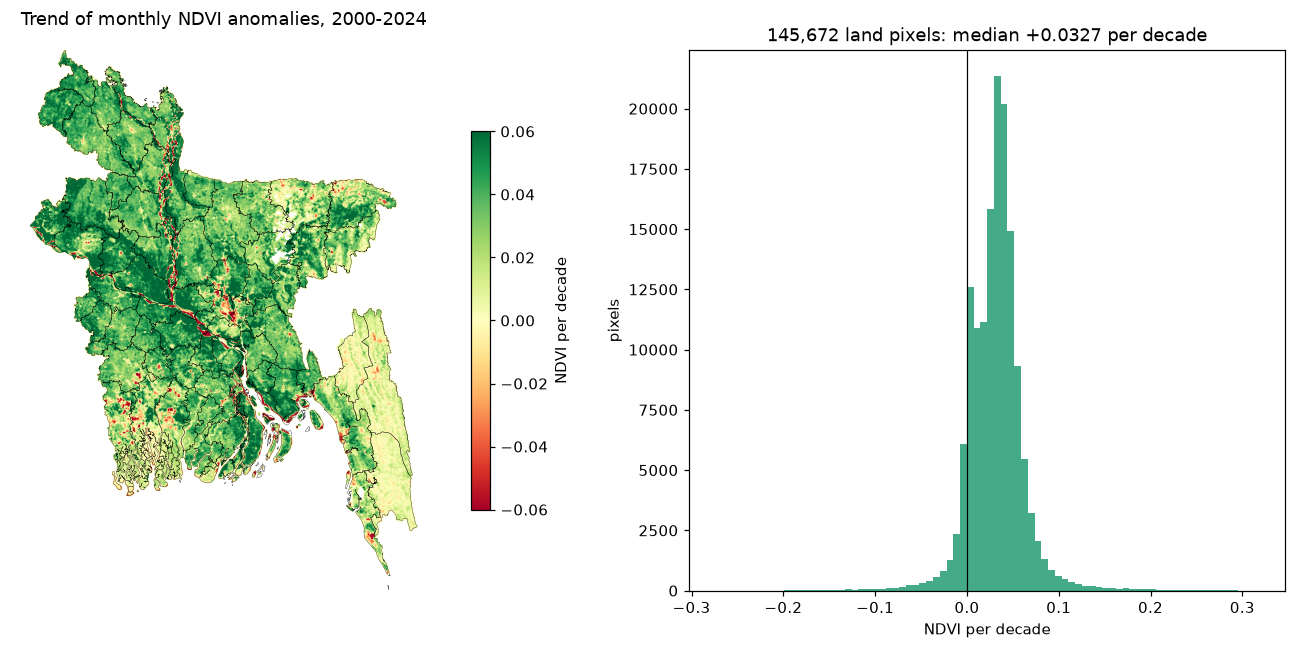

pixels greening by more than 0.02 per decade: 69.5%; browning by more than 0.02: 2.6%


,pixels,median trend,share > +0.02,share < -0.02
district,,,,
Pabna,2386,0.060,0.953,0.010
Nawabganj,1691,0.056,0.895,0.028
Natore,1903,0.051,0.960,0.011
Faridpur,2047,0.051,0.942,0.022
Bandarban,4602,0.004,0.021,0.002
Khagrachhari,2858,0.004,0.076,0.004
Rangamati,5774,0.007,0.076,0.014
Khulna,3600,0.012,0.331,0.049


In [9]:
# Write the trend GeoTIFF, summarize by district, and plot map + histogram
trend_map = np.full(shape, np.nan, dtype="float32")
trend_map[land] = trend
profile = dict(driver="GTiff", width=shape[1], height=shape[0], count=1, dtype="float32", crs=crs, transform=transform,
               nodata=np.nan, compress="deflate", tiled=True, blockxsize=256, blockysize=256)
with rasterio.open(OUT / "ndvi_anomaly_trend.tif", "w", **profile) as dst:
    dst.write(trend_map, 1)
    dst.set_band_description(1, "Theil-Sen slope of monthly NDVI anomalies, per decade, 2000-2024")

# District-level summary of greening and browning shares
districts = gpd.read_file(WEB / "08_03_outputs" / "districts.gpkg").to_crs(crs)
summary = []
for name, geom in zip(districts.district, districts.geometry):
    inside = geometry_mask([mapping(geom)], out_shape=shape, transform=transform, invert=True) & land
    v = trend_map[inside]
    summary.append({"district": name, "pixels": int(inside.sum()), "median trend": float(np.nanmedian(v)),
                    "share > +0.02": float((v > 0.02).mean()), "share < -0.02": float((v < -0.02).mean())})
summary = pd.DataFrame(summary).set_index("district")

# Map and histogram of per-pixel anomaly trends
fig, ax = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.15, 1]})
extent = [transform.c, transform.c + transform.a * shape[1], transform.f + transform.e * shape[0], transform.f]
im = ax[0].imshow(trend_map, cmap="RdYlGn", vmin=-0.06, vmax=0.06, extent=extent)
districts.boundary.plot(ax=ax[0], color="black", linewidth=0.2)
ax[0].set_title("Trend of monthly NDVI anomalies, 2000-2024"); ax[0].set_axis_off()
fig.colorbar(im, ax=ax[0], shrink=0.7, label="NDVI per decade")
ax[1].hist(trend[np.isfinite(trend)], bins=80, color="#4a8")
ax[1].axvline(0, color="k", lw=0.8); ax[1].set_xlabel("NDVI per decade"); ax[1].set_ylabel("pixels")
ax[1].set_title(f"{n_pix:,} land pixels: median {np.nanmedian(trend):+.4f} per decade")
plt.tight_layout(); plt.show()
print(f"pixels greening by more than 0.02 per decade: {(trend > 0.02).mean():.1%}; browning by more than 0.02: {(trend < -0.02).mean():.1%}")
display(pd.concat([summary.nlargest(4, "median trend"), summary.nsmallest(4, "median trend")]).round(3))

Vegetation has become greener across most of Bangladesh: the median trend is +0.033 NDVI per
decade, 69.5% of land pixels gained more than 0.02 per decade and only 2.6% lost that much.

- **Strongest greening:** the north-west and centre-west (Pabna, Nawabganj, Natore, with medians
  of 0.05-0.06 per decade and over 89% of pixels greening) and Faridpur. These are areas of
  intensified, irrigated cropping.
- **Little change:** the forested Chittagong Hill Tracts (Bandarban, Khagrachhari, Rangamati,
  medians 0.004-0.007), whose NDVI is already near its ceiling.
- **Weaker trends:** the south-western coast (Khulna median 0.012, 4.9% browning).
- **Browning:** concentrated along the Jamuna and Padma rivers, where channels and sandbars move,
  and in patches around the cities, consistent with urban growth.

This is a statistical trend in a vegetation index. Attributing it to irrigation, cropping
intensity, urbanisation or salinity needs ancillary data.

## Reading from the cloud in parallel

In the cloud the input is usually remote. A STAC search finds every Sentinel-2 scene of tile 18TVN
(Syracuse, NY) with less than 20 % cloud between April and October 2025; we then read the same 12 km
window of the red band from 12 of them, serially and with 4, 8 and 16 threads, counting the bytes GDAL
downloads. GDAL's Python bindings release the GIL during reads, so threads can overlap the waiting.

In [10]:
# Remote COG window reads via STAC + GDAL /vsicurl; scale with thread pools
# STAC search + GDAL config for range reads of remote COGs
from pystac_client import Client as STACClient
import pyproj

BOX = (-76.20, 43.00, -76.08, 43.08)
OPTIONS = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", AWS_NO_SIGN_REQUEST="YES", GDAL_HTTP_MULTIRANGE="YES",
               GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
               CPL_VSIL_NETWORK_STATS_ENABLED="YES", VSI_CACHE="FALSE", CPL_VSIL_CURL_NON_CACHED="/vsicurl/")
for k, v in OPTIONS.items():
    gdal.SetConfigOption(k, v)

# Read one bbox window and return its mean
def read_window(href):
    "Read the BOX window of a remote COG band with GDAL; return its mean."
    ds = gdal.Open("/vsicurl/" + href)
    gt = ds.GetGeoTransform()
    tr = pyproj.Transformer.from_crs(4326, ds.GetSpatialRef().ExportToWkt(), always_xy=True)
    (x0, y1), (x1, y0) = tr.transform(BOX[0], BOX[3]), tr.transform(BOX[2], BOX[1])
    c0, r0 = int((x0 - gt[0]) / gt[1]), int((y1 - gt[3]) / gt[5])
    c1, r1 = int((x1 - gt[0]) / gt[1]), int((y0 - gt[3]) / gt[5])
    return float(ds.GetRasterBand(1).ReadAsArray(c0, r0, c1 - c0, r1 - r0).mean())

def downloaded():
    stats = json.loads(gdal.NetworkStatsGetAsSerializedJSON() or "{}")
    return sum(m.get("downloaded_bytes", 0) for m in stats.get("methods", {}).values())

# Search Sentinel-2, then time threaded window reads
try:
    t0 = time.perf_counter()
    items = list(STACClient.open("https://earth-search.aws.element84.com/v1").search(
        collections=["sentinel-2-l2a"], bbox=BOX, datetime="2025-04-01/2025-10-31", query={"eo:cloud_cover": {"lt": 20}}).items())
    tile = [it for it in items if it.properties.get("mgrs:utm_zone") == 18 and it.properties.get("mgrs:grid_square") == "VN"]
    hrefs = [it.assets["red"].href for it in sorted(tile, key=lambda it: it.datetime)][:12]
    print(f"STAC search: {len(items)} scenes, {len(tile)} on tile 18TVN, in {time.perf_counter() - t0:.1f} s; reading {len(hrefs)}")
    rows = []
    for threads in [1, 4, 8, 16]:
        gdal.NetworkStatsReset()
        t0 = time.perf_counter()
        if threads == 1:
            means = [read_window(h) for h in hrefs]
        else:
            with ThreadPoolExecutor(threads) as ex:
                means = list(ex.map(read_window, hrefs))
        sec = time.perf_counter() - t0
        mb = downloaded() / 1e6
        rows.append({"threads": threads, "seconds": sec, "MB downloaded": mb, "MB/s": mb / sec})
    remote = pd.DataFrame(rows).set_index("threads")
    remote["speed-up"] = remote.seconds.iloc[0] / remote.seconds
    display(remote.round(2))
except Exception as exc:
    remote = None
    print("Remote reads skipped:", type(exc).__name__, exc)

STAC search: 51 scenes, 26 on tile 18TVN, in 3.3 s; reading 12


,seconds,MB downloaded,MB/s,speed-up
threads,,,,
1,35.97,70.29,1.95,1.00
4,23.65,70.29,2.97,1.52
8,14.50,70.29,4.85,2.48
16,14.74,70.29,4.77,2.44


The 12 windows total 70.3 MB of compressed data.

| Threads | Time | Throughput | Speed-up |
|---|---|---|---|
| 1 | 36.0 s | 1.95 MB/s | 1× |
| 4 | 23.7 s | 2.97 MB/s | 1.5× |
| 8 | 14.5 s | 4.85 MB/s | 2.5× |
| 16 | 14.7 s | 4.77 MB/s | 2.4× |

Beyond 8 threads nothing improved: this machine's internet link to AWS us-west-2 was saturated at
about 5 MB/s. Remote work is bounded by bandwidth and latency, not by cores. Inside the same cloud
region as the data, throughput is typically hundreds of MB/s, which is why large analyses run where
the data are (Notebook 08_09).

These numbers depend on the network and vary between runs.

## Batch jobs: the serverless pattern, and what a run costs

Cloud batch services (AWS Batch, Google Cloud Batch and Cloud Run jobs, Azure Batch) and serverless
functions all run the same unit: an **independent job** that reads its piece of input from object
storage, writes its own output, and exits. A coordinator starts one job per piece (a *job array*)
and combines the outputs. Jobs must be **idempotent**: re-running one gives the same output, so
failed or duplicated jobs are harmless.

We imitate this with separate operating-system processes: the trend calculation is split into 8 jobs
by pixel range, each a fresh Python process with its own arguments, as a container would be.

In [11]:
# Idempotent batch jobs: split pixels across processes, re-run, and recover a "lost" part
job_code = '''import json, sys, time
from pathlib import Path
import numpy as np

def theil_sen(a):
    n = a.shape[0]
    i, j = np.triu_indices(n, 1)
    return (np.nanmedian((a[j] - a[i]) / (j - i).astype("float32")[:, None], axis=0) * 120).astype("float32")

src, start, stop, out = sys.argv[1], int(sys.argv[2]), int(sys.argv[3]), Path(sys.argv[4])
done = out.with_suffix(".json")
if done.exists():                                   # idempotent: finished jobs are skipped
    sys.exit(0)
t0 = time.perf_counter()
a = np.load(src, mmap_mode="r")
res = np.concatenate([theil_sen(np.asarray(a[:, k:min(k + 250, stop)])) for k in range(start, stop, 250)])
np.save(out, res)
done.write_text(json.dumps({"start": start, "stop": stop, "seconds": time.perf_counter() - t0}))
'''
(OUT / "trend_job.py").write_text(job_code)
jobs_dir = OUT / "jobs"; jobs_dir.mkdir()
bounds = np.linspace(0, n_pix, 9).astype(int)

# Launch one process per pixel slice
def run_jobs():
    procs = [subprocess.Popen([sys.executable, str(OUT / "trend_job.py"), str(OUT / "anomalies.npy"), str(a), str(b),
                               str(jobs_dir / f"part_{k:02d}.npy")]) for k, (a, b) in enumerate(zip(bounds[:-1], bounds[1:]))]
    return [p.wait() for p in procs]

t0 = time.perf_counter(); codes = run_jobs(); wall = time.perf_counter() - t0
manifest = [json.loads(p.read_text()) for p in sorted(jobs_dir.glob("*.json"))]
combined = np.concatenate([np.load(jobs_dir / f"part_{k:02d}.npy") for k in range(8)])
print(f"8 jobs, exit codes {codes}: wall time {wall:.1f} s; job times {[round(m['seconds'], 1) for m in manifest]} s")
print("identical to the Dask result:", np.allclose(combined, trend, equal_nan=True))
t0 = time.perf_counter(); run_jobs(); print(f"re-run: {time.perf_counter() - t0:.1f} s (all jobs already done, nothing recomputed)")
(jobs_dir / "part_03.json").unlink()                 # pretend job 3 failed
t0 = time.perf_counter(); run_jobs(); print(f"after 'losing' job 3: {time.perf_counter() - t0:.1f} s (only job 3 ran again)")
job_cpu_s = sum(m["seconds"] for m in manifest)

8 jobs, exit codes [0, 0, 0, 0, 0, 0, 0, 0]: wall time 17.1 s; job times [17.0, 16.9, 16.2, 16.8, 16.5, 16.1, 16.5, 16.8] s
identical to the Dask result: True
re-run: 0.1 s (all jobs already done, nothing recomputed)


after 'losing' job 3: 13.3 s (only job 3 ran again)


**What would a run cost?** Cloud compute is billed by resource-time. The prices below are
**illustrative assumptions** for on-demand capacity (they vary by provider, region, purchase option
and over time; check the provider's price list). The compute times are the ones measured above.

In [12]:
# Illustrative cost comparison across sequential, Dask, batch, serverless, and GPU setups
PRICE_VCPU_HOUR = 0.045        # assumption: USD per vCPU-hour, general-purpose on-demand instance
PRICE_GPU_HOUR = 1.00          # assumption: USD per hour for a single-GPU instance
PRICE_LAMBDA_GB_S = 0.0000167  # assumption: USD per GB-second of serverless function time
runs = {
    "1 vCPU, sequential": (serial_s / SUB * n_pix, 1, "vcpu"),
    "8 vCPUs, Dask": (dask_full, 8, "vcpu"),
    "8 batch jobs (1 vCPU each)": (job_cpu_s / 8, 8, "vcpu"),
    "8 serverless functions (2 GB each)": (job_cpu_s / 8, 8, "lambda"),
}
if GPU:
    runs["1 GPU instance"] = (gpu_full, 1, "gpu")
rows = []
for name, (seconds, n, kind) in runs.items():
    cost = (seconds / 3600 * n * PRICE_VCPU_HOUR if kind == "vcpu" else
            seconds / 3600 * PRICE_GPU_HOUR if kind == "gpu" else seconds * n * 2 * PRICE_LAMBDA_GB_S)
    rows.append({"setup": name, "wall time s": seconds, "resource-seconds": seconds * n, "cost USD (illustrative)": cost,
                 "cost per 1,000 runs USD": cost * 1000})
pd.DataFrame(rows).set_index("setup").round(4)

,wall time s,resource-seconds,cost USD (illustrative),"cost per 1,000 runs USD"
setup,,,,
"1 vCPU, sequential",99.2582,99.2582,0.0012,1.2407
"8 vCPUs, Dask",20.0724,160.5790,0.0020,2.0072
8 batch jobs (1 vCPU each),16.5775,132.6204,0.0017,1.6578
8 serverless functions (2 GB each),16.5775,132.6204,0.0044,4.4295
1 GPU instance,9.9080,9.9080,0.0028,2.7522


The 8 independent jobs finished in 17.1 s, slightly faster than Dask (20.1 s) because they skip
the scheduler. Each job took about 16-17 s against roughly 12 s if it had the machine to itself:
the memory-bandwidth contention of Section 6 again. Re-running did nothing (0.1 s), because every
job found its completion record. After one record was deleted, only that job ran again (13.3 s).
This is what makes retries and spot or preemptible instances safe.

With the illustrative prices, the whole national trend costs a fraction of a cent per run, from
USD 0.0012 (one vCPU, sequential) to 0.0044 (eight serverless functions). For a job this size the
price hardly matters: time and simplicity decide. The ranking matters at scale:

- **Parallel CPU runs** cost more than sequential ones, because imperfect scaling wastes
  resource-seconds: 161 against 99 vCPU-seconds.
- **Serverless** charges a premium for its convenience.
- **A GPU** is fastest, and cheaper per run than parallel CPU only when it is kept busy.

Before scaling out to many machines, remember what the measurements showed. Most of the gain came
from using this machine well (processes, the right chunk size, a GPU), and the network, not the
number of cores, limited remote reads. Scale out when one machine's memory, disk or bandwidth is
exhausted, and move the computation to the data's region rather than the data to the computation.

In [13]:
# Clean temporary arrays and job shards; keep durable outputs
for p in OUT.glob("*.zarr"):
    shutil.rmtree(p)
for p in [OUT / "anomalies.npy", OUT / "subset.npy"]:
    p.unlink()
shutil.rmtree(jobs_dir)
print("kept:", sorted(p.name for p in OUT.iterdir()))

kept: ['ndvi_anomaly_trend.tif', 'trend_job.py']


## Summary and exercises

**Key ideas**

- Measure first: the slow part may be reading, memory bandwidth or the network rather than arithmetic.
- Dask builds lazy, chunked pipelines that run on threads, processes or clusters with the same code.
- Chunk shape decides which reads are cheap: chunk for the access pattern you serve.
- Processes avoid the GIL; speed-up then stops at a limit set by the hardware (Amdahl's law in practice).
- GPUs suit regular, data-parallel kernels; CuPy runs NumPy-style code on them with few changes.
- Batch jobs that are independent and idempotent are the unit of serverless and cloud batch processing;
  cost follows resource-time.

**What we measured on one laptop-class machine (16 cores, one GPU)**

- **Reading 572 images:** 3.3 s serially, 4.4 s with threads (GIL), 0.66 s with 8 processes.
- **Zarr chunks:** a pixel's time series took 182 ms chunked by date against 5.5 ms chunked by space;
  a single map the reverse (1.1 against 41 ms).
- **Theil-Sen on 145,672 pixels:** 99 s on one core, 20.1 s with Dask (4.9×), 9.9 s on the GPU
  (10×). Dask scaling flattened beyond 4-8 workers (memory bandwidth).
- **Result:** 69.5% of land pixels greened by more than 0.02 NDVI per decade; browning followed
  rivers and cities.
- **Remote reads:** the network saturated at about 5 MB/s, so 8 threads gave 2.5× and 16 no more.
- **Batch jobs:** 8 independent, idempotent jobs took 17.1 s and re-ran only what was missing; a full
  run costs well under one US cent at illustrative prices.

**Exercises**

1. Replace `nanmedian` by `np.partition`-based medians (no NaNs after filtering). How much faster is
   the CPU kernel, and does the Dask speed-up curve change?
2. Compute the Mann-Kendall statistic alongside the Theil-Sen slope on the GPU, and map pixels with
   significant trends (take care: monthly anomalies are autocorrelated).
3. Rechunk the Zarr store to (572, 128, 128) with `dask.array.rechunk` and repeat the read timings of
   Section 5. What is the trade-off?
4. Run Section 9 with rasterio instead of GDAL in the threads. Explain the difference.
5. Using the illustrative prices, at how many runs per month does buying a GPU workstation pay off?

**References**

- Rocklin, M. (2015). Dask: Parallel computation with blocked algorithms and task scheduling. *Proc. 14th Python in Science Conference*, 130-136.
- Hoyer, S. & Hamman, J. (2017). xarray: N-D labeled arrays and datasets in Python. *Journal of Open Research Software*, 5(1).
- Abernathey, R. P. et al. (2021). Cloud-native repositories for big scientific data. *Computing in Science & Engineering*, 23(2), 26-35.
- Sen, P. K. (1968). Estimates of the regression coefficient based on Kendall's tau. *JASA*, 63, 1379-1389.
- Okuta, R. et al. (2017). CuPy: A NumPy-compatible library for NVIDIA GPU calculations. *Proc. LearningSys, NIPS*.
- Amdahl, G. M. (1967). Validity of the single processor approach to achieving large scale computing capabilities. *AFIPS Conference Proceedings*, 30, 483-485.